In [5]:
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display  

In [16]:
class State(TypedDict):
    name: str
    performanece_score: int
    years_of_experience: int
    result : str

In [35]:
def check_employee(state: State):
    return {"name" : state["name"], "performanece_score" : state["performanece_score"], "years_of_experience" : state['years_of_experience']}

def eligible(state: State):
    return {"result": "You are eligible for bonus!!!"}

def not_eligible(state: State):
    return {"result": "You are not eligible for bonus!!!"}

def check_eligibility(state: State):
    if state['performanece_score'] >= 70:
        return "eligible"
    else:
        return "not_eligible"

def senior_bonus(state: State):
    return {"result": "You are eligible for senior bonus!!!"}

def not_senior_bonus(state: State):
    return {"result": "You are not eligible for senior bonus!!!"}

def check_senior_bonus(state: State):
    if state['years_of_experience'] >= 5:
        return "senior_bonus"
    else:
        return "not_senior_bonus"

    
graph = StateGraph(State)

graph.add_node("check_employee", check_employee)
graph.add_node("eligible", eligible)
graph.add_node("not_eligible", not_eligible)
graph.add_node("senior_bonus", senior_bonus)
graph.add_node("not_senior_bonus", not_senior_bonus)


graph.add_edge(START, "check_employee")
graph.add_conditional_edges("check_employee", check_eligibility, {"eligible": "eligible", "not_eligible": "not_eligible"})
graph.add_edge("not_eligible", END)
graph.add_conditional_edges("eligible", check_senior_bonus, {"senior_bonus": "senior_bonus", "not_senior_bonus": "not_senior_bonus"})
graph.add_edge("senior_bonus", END)
graph.add_edge("not_senior_bonus", END)

In [36]:
graph_builder = graph.compile()

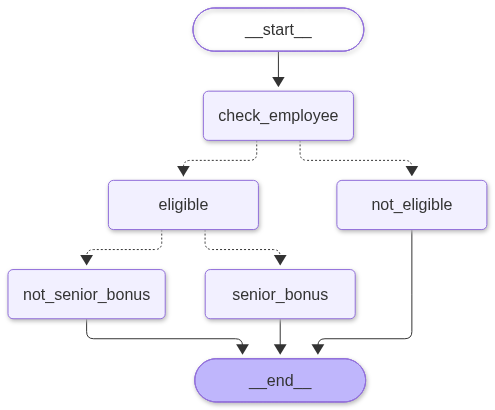

In [30]:
display(Image(graph_builder.get_graph().draw_mermaid_png()))

In [38]:
graph_builder.invoke({"name": "John Doe", "performanece_score": 80, "years_of_experience": 6, "result" : ""})

{'name': 'John Doe',
 'performanece_score': 80,
 'years_of_experience': 6,
 'result': 'You are eligible for senior bonus!!!'}